# Tutorial: Support Vector Machines (SVMs) in scikit-learn

This notebook introduces **Support Vector Machines (SVMs)** using `scikit-learn`.

The tutorial focuses on:

- basic SVM intuition,
- using `SVC` in scikit-learn,
- why feature scaling matters,
- effects of important hyperparameters,
- visualizing decision boundaries,
- tuning SVMs with `GridSearchCV`,
- handling imbalanced datasets using `class_weight`.

We use a 2D non-linear dataset so that the effect of each hyperparameter is visible.


## 1. Core idea of Support Vector Machines

A Support Vector Machine tries to find a decision boundary that separates classes with a **large margin**.

The training samples closest to the decision boundary are called **support vectors**.

These support vectors are important because they strongly influence where the boundary is placed.

For a binary classification problem:

- a **linear SVM** creates a straight decision boundary,
- a **non-linear SVM** can create curved boundaries using kernels,
- the most common non-linear kernel is the **RBF kernel**.


## 2. Important SVM hyperparameters

| Hyperparameter | Main role |
|---|---|
| `kernel` | Controls the shape of the decision boundary |
| `C` | Controls the penalty for classification errors |
| `gamma` | Controls the influence range of training points, especially for RBF kernels |
| `degree` | Controls polynomial complexity when `kernel="poly"` |
| `class_weight` | Adjusts class penalties for imbalanced datasets |

A practical starting point is usually:

```python
SVC(kernel="rbf", C=1.0, gamma="scale")
```

However, this is not always optimal. We should inspect and tune the parameters.


## 3. Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons, make_blobs
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC, LinearSVC
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
from sklearn.inspection import DecisionBoundaryDisplay

np.random.seed(42)


## 4. Create a non-linear dataset

We use `make_moons` because it is not linearly separable.

This is a good dataset for teaching SVMs because:

- a linear boundary is not enough,
- an RBF kernel works better,
- high and low values of `C` and `gamma` visibly change the boundary.


X shape: (3000, 2)
y shape: (3000,)
Class distribution:
0    1500
1    1500
Name: count, dtype: int64


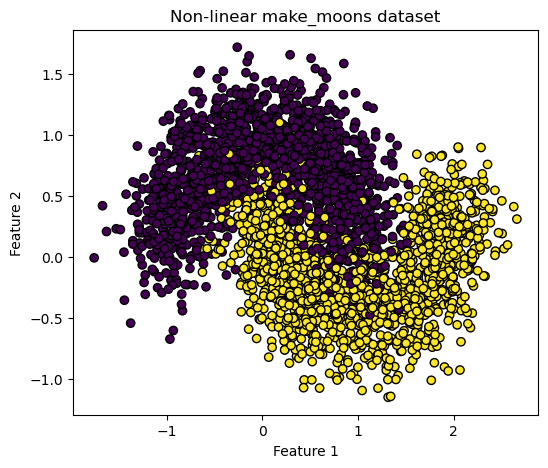

In [2]:
X, y = make_moons(
    n_samples=3000,
    noise=0.25,
    random_state=42
)

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Class distribution:")
print(pd.Series(y).value_counts().sort_index())

plt.figure(figsize=(6, 5))
plt.scatter(X[:, 0], X[:, 1], c=y, edgecolor="k")
plt.title("Non-linear make_moons dataset")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()


## 5. Train-test split

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Test samples:", X_test.shape[0])


Training samples: 2100
Test samples: 900


## 6. Why scaling matters

SVMs are sensitive to feature scales because they rely on distances and margins.

Therefore, we usually combine:

```python
StandardScaler()
SVC()
```

inside a `Pipeline`.

This prevents data leakage because the scaler is fitted only on the training data.


In [4]:
baseline_model = Pipeline([
    ("scaler", StandardScaler()),
    ("svc", SVC(kernel="rbf", C=1.0, gamma="scale"))
])

baseline_model.fit(X_train, y_train)

y_pred = baseline_model.predict(X_test)

print("Baseline RBF SVM accuracy:", accuracy_score(y_test, y_pred))
print()
print(classification_report(y_test, y_pred))


Baseline RBF SVM accuracy: 0.9433333333333334

              precision    recall  f1-score   support

           0       0.96      0.92      0.94       450
           1       0.93      0.96      0.94       450

    accuracy                           0.94       900
   macro avg       0.94      0.94      0.94       900
weighted avg       0.94      0.94      0.94       900



## 7. Helper functions

The following functions will help us train models, evaluate them, and visualize their decision boundaries.

Because the dataset has only two features, we can draw the decision surface.


In [5]:
def evaluate_model(model, X_train, y_train, X_test, y_test):
    """Fit a model and return training and test accuracy."""
    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    train_acc = accuracy_score(y_train, train_pred)
    test_acc = accuracy_score(y_test, test_pred)

    return train_acc, test_acc


def plot_decision_boundary(model, X, y, title):
    """Fit a model and plot its decision boundary."""
    model.fit(X, y)

    plt.figure(figsize=(6, 5))

    DecisionBoundaryDisplay.from_estimator(
        model,
        X,
        response_method="predict",
        plot_method="pcolormesh",
        alpha=0.35,
        xlabel="Feature 1",
        ylabel="Feature 2",
    )

    plt.scatter(X[:, 0], X[:, 1], c=y, edgecolor="k")
    plt.title(title)
    plt.show()


def make_svm(kernel="rbf", C=1.0, gamma="scale", degree=3, class_weight=None):
    """Create a standard SVM pipeline."""
    return Pipeline([
        ("scaler", StandardScaler()),
        ("svc", SVC(
            kernel=kernel,
            C=C,
            gamma=gamma,
            degree=degree,
            class_weight=class_weight
        ))
    ])


## 8. Effect of different kernels

The `kernel` parameter controls the type of decision boundary.

Common choices:

- `linear`: straight boundary,
- `poly`: polynomial boundary,
- `rbf`: flexible smooth non-linear boundary,
- `sigmoid`: neural-network-like kernel, less commonly used in practice.

We compare them below.


In [6]:
kernels = ["linear", "poly", "rbf", "sigmoid"]

kernel_results = []

for kernel in kernels:
    model = make_svm(kernel=kernel, C=1.0, gamma="scale", degree=3)
    train_acc, test_acc = evaluate_model(model, X_train, y_train, X_test, y_test)

    kernel_results.append({
        "kernel": kernel,
        "train_accuracy": train_acc,
        "test_accuracy": test_acc
    })

pd.DataFrame(kernel_results)


,kernel,train_accuracy,test_accuracy
0,linear,0.849048,0.872222
1,poly,0.849048,0.864444
2,rbf,0.928571,0.943333
3,sigmoid,0.659048,0.682222


<Figure size 600x500 with 0 Axes>

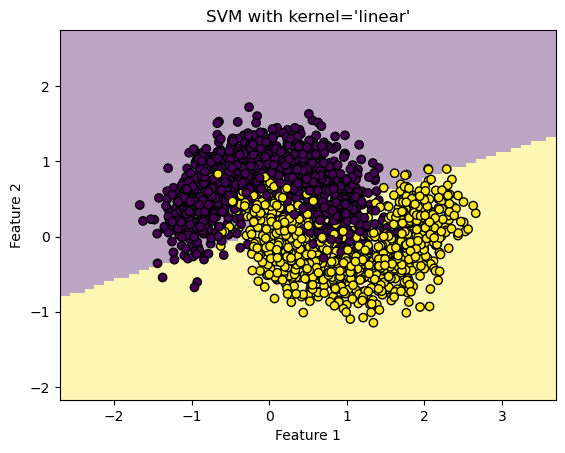

<Figure size 600x500 with 0 Axes>

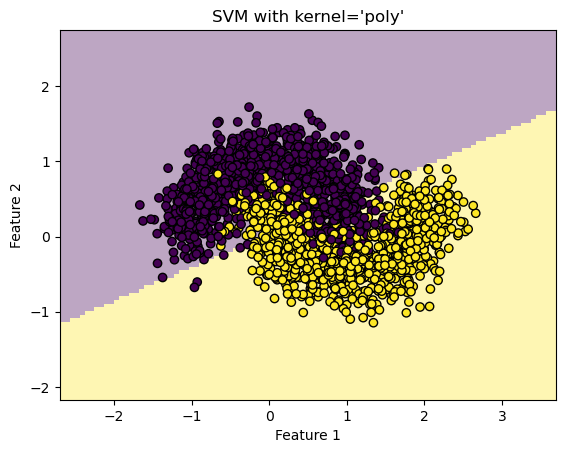

<Figure size 600x500 with 0 Axes>

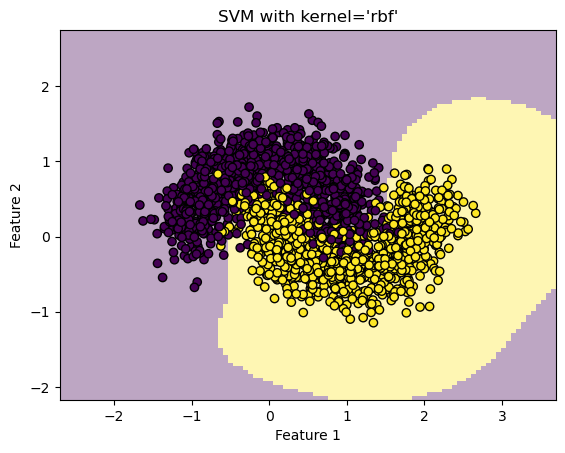

<Figure size 600x500 with 0 Axes>

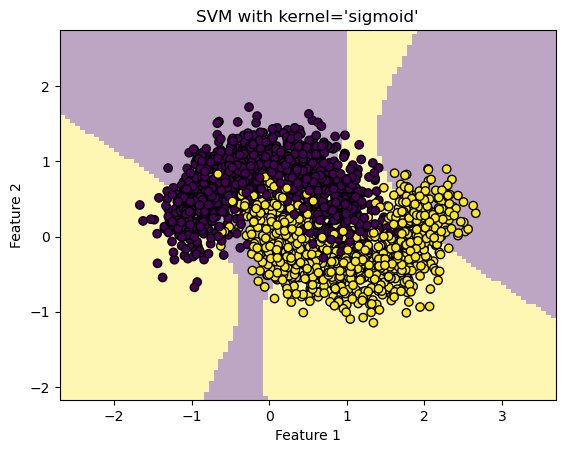

In [7]:
for kernel in kernels:
    model = make_svm(kernel=kernel, C=1.0, gamma="scale", degree=3)
    plot_decision_boundary(
        model,
        X_train,
        y_train,
        title=f"SVM with kernel='{kernel}'"
    )


### Interpretation

The linear kernel usually underfits this dataset because the two classes have a curved structure.

The RBF kernel often works well because it can create a smooth non-linear boundary.

The polynomial kernel can also work, but its behavior depends strongly on `degree`, `C`, and `gamma`.

The sigmoid kernel is usually not the first choice for this type of dataset.


## 9. Effect of `C`

`C` controls how strongly the model tries to classify training points correctly.

### Small `C`

A small `C` means stronger regularization.

The model allows more classification errors in order to keep the boundary smoother.

### Large `C`

A large `C` means weaker regularization.

The model tries harder to classify training points correctly.

This can improve training accuracy but may cause overfitting.


In [8]:
C_values = [0.01, 0.1, 1, 10, 100]

C_results = []

for C in C_values:
    model = make_svm(kernel="rbf", C=C, gamma="scale")
    train_acc, test_acc = evaluate_model(model, X_train, y_train, X_test, y_test)

    C_results.append({
        "C": C,
        "train_accuracy": train_acc,
        "test_accuracy": test_acc
    })

pd.DataFrame(C_results)


,C,train_accuracy,test_accuracy
0,0.01,0.880952,0.894444
1,0.10,0.915238,0.934444
2,1.00,0.928571,0.943333
3,10.00,0.930476,0.942222
4,100.00,0.929048,0.941111


<Figure size 600x500 with 0 Axes>

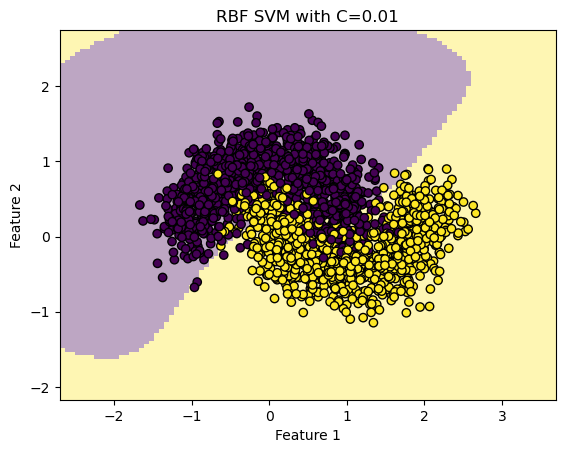

<Figure size 600x500 with 0 Axes>

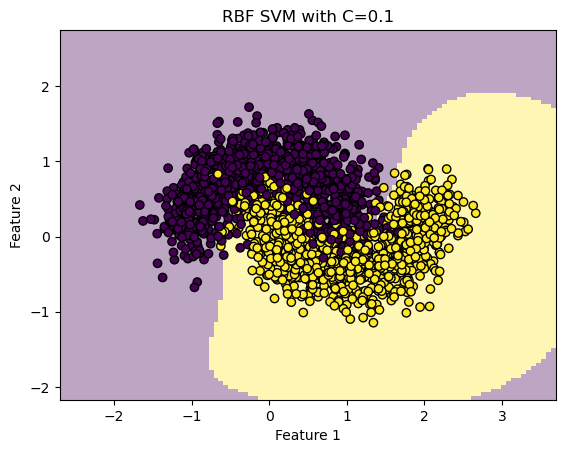

<Figure size 600x500 with 0 Axes>

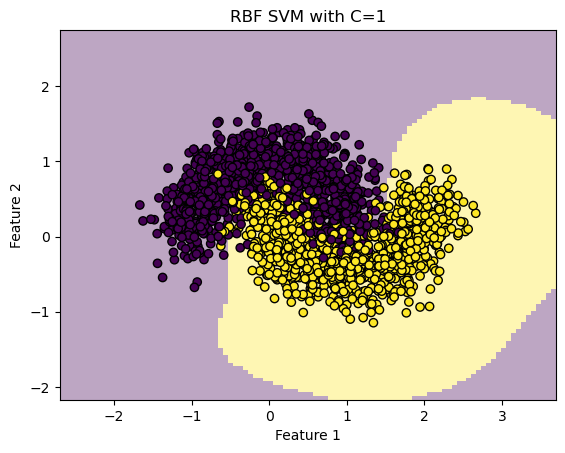

<Figure size 600x500 with 0 Axes>

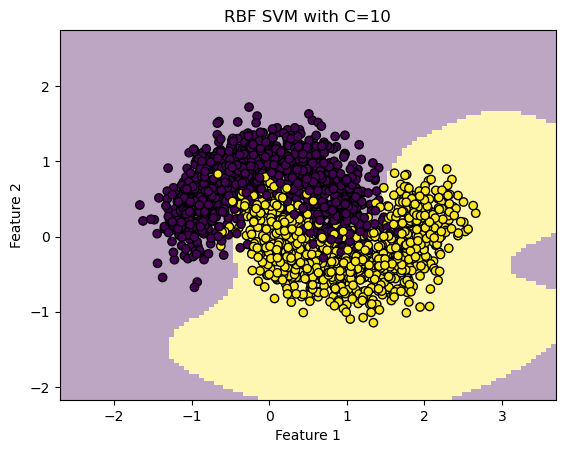

<Figure size 600x500 with 0 Axes>

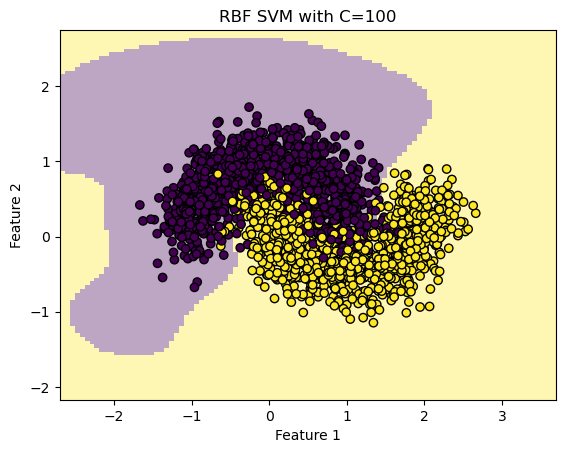

In [9]:
for C in C_values:
    model = make_svm(kernel="rbf", C=C, gamma="scale")
    plot_decision_boundary(
        model,
        X_train,
        y_train,
        title=f"RBF SVM with C={C}"
    )


### Interpretation of `C`

| Value of `C` | Expected effect |
|---|---|
| Very small | Strong regularization, smooth boundary, possible underfitting |
| Medium | Balanced complexity |
| Very large | Weak regularization, complex boundary, possible overfitting |

Important point:

`C` does not change the kernel itself.  
It changes how much the model penalizes classification mistakes.


## 10. Effect of `gamma`

`gamma` is especially important for the RBF kernel.

It controls how far the influence of a training point reaches.

### Small `gamma`

Each point has a broad influence.

The decision boundary becomes smoother.

### Large `gamma`

Each point has a narrow local influence.

The decision boundary becomes more detailed and may overfit.


In [10]:
gamma_values = [0.01, 0.1, 1, 10, 100]

gamma_results = []

for gamma in gamma_values:
    model = make_svm(kernel="rbf", C=1.0, gamma=gamma)
    train_acc, test_acc = evaluate_model(model, X_train, y_train, X_test, y_test)

    gamma_results.append({
        "gamma": gamma,
        "train_accuracy": train_acc,
        "test_accuracy": test_acc
    })

pd.DataFrame(gamma_results)


,gamma,train_accuracy,test_accuracy
0,0.01,0.850476,0.871111
1,0.10,0.889048,0.902222
2,1.00,0.929524,0.942222
3,10.00,0.936190,0.941111
4,100.00,0.959048,0.930000


<Figure size 600x500 with 0 Axes>

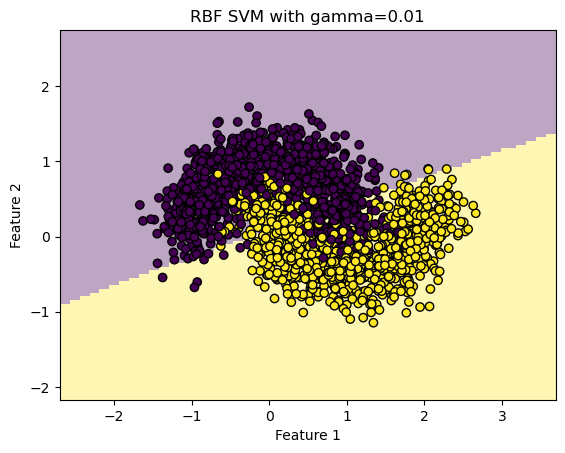

<Figure size 600x500 with 0 Axes>

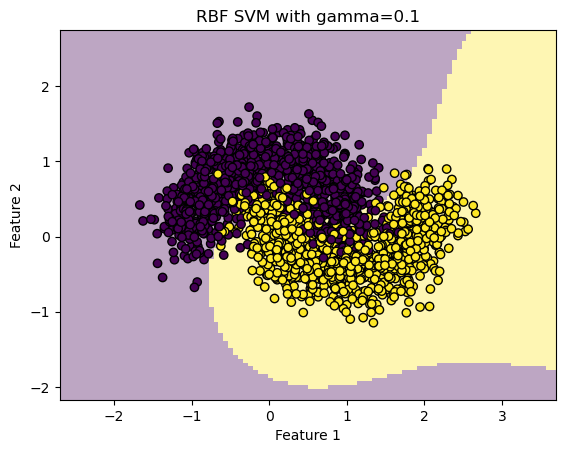

<Figure size 600x500 with 0 Axes>

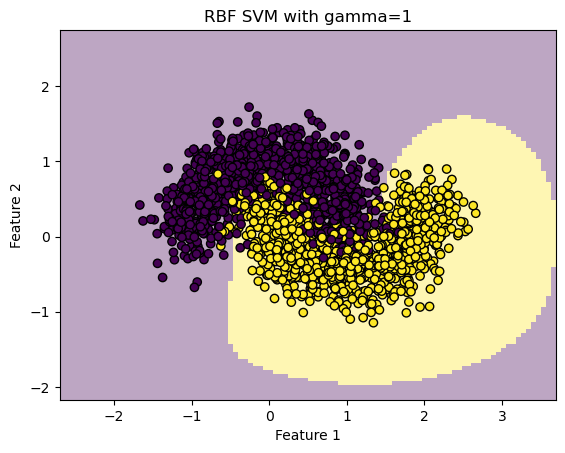

<Figure size 600x500 with 0 Axes>

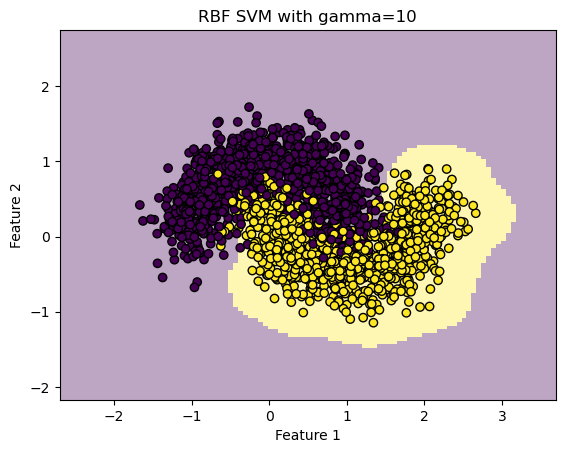

<Figure size 600x500 with 0 Axes>

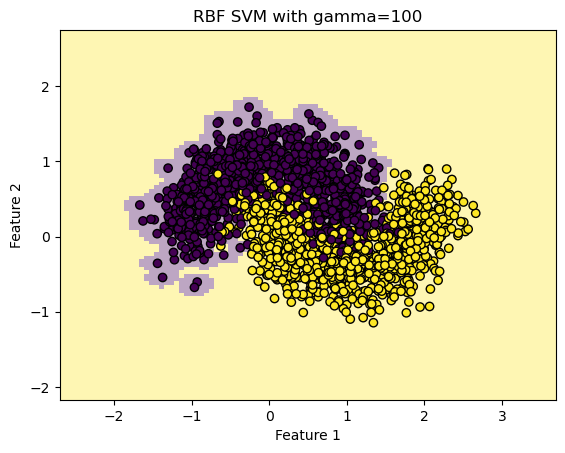

In [11]:
for gamma in gamma_values:
    model = make_svm(kernel="rbf", C=1.0, gamma=gamma)
    plot_decision_boundary(
        model,
        X_train,
        y_train,
        title=f"RBF SVM with gamma={gamma}"
    )


### Interpretation of `gamma`

| Value of `gamma` | Expected effect |
|---|---|
| Very small | Boundary is too smooth, possible underfitting |
| Medium | Balanced decision boundary |
| Very large | Boundary becomes highly local, possible overfitting |

A common teaching phrase:

> `C` controls how much the model dislikes mistakes.  
> `gamma` controls how local the influence of each training point is.


## 11. Combined effect of `C` and `gamma`

`C` and `gamma` interact.

The most risky setting is usually:

```python
C = high
gamma = high
```

This combination can produce a very flexible boundary that memorizes noisy data.


In [12]:
C_grid = [0.1, 1, 10]
gamma_grid = [0.1, 1, 10]

combined_results = []

for C in C_grid:
    for gamma in gamma_grid:
        model = make_svm(kernel="rbf", C=C, gamma=gamma)
        train_acc, test_acc = evaluate_model(model, X_train, y_train, X_test, y_test)

        combined_results.append({
            "C": C,
            "gamma": gamma,
            "train_accuracy": train_acc,
            "test_accuracy": test_acc
        })

pd.DataFrame(combined_results)


,C,gamma,train_accuracy,test_accuracy
0,0.1,0.1,0.856667,0.875556
1,0.1,1.0,0.927619,0.944444
2,0.1,10.0,0.933810,0.941111
3,1.0,0.1,0.889048,0.902222
4,1.0,1.0,0.929524,0.942222
5,1.0,10.0,0.936190,0.941111
6,10.0,0.1,0.918571,0.937778
7,10.0,1.0,0.932381,0.942222
8,10.0,10.0,0.943333,0.938889


<Figure size 600x500 with 0 Axes>

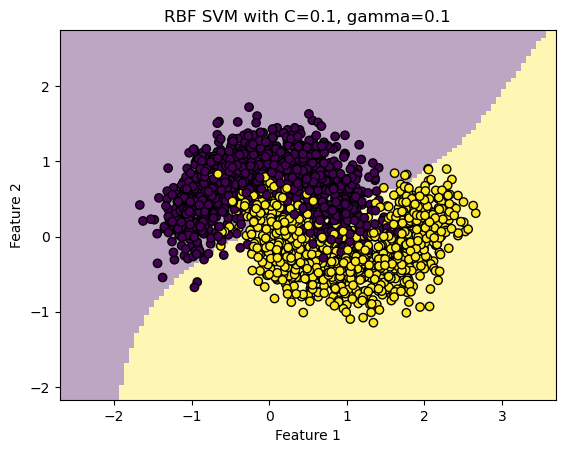

<Figure size 600x500 with 0 Axes>

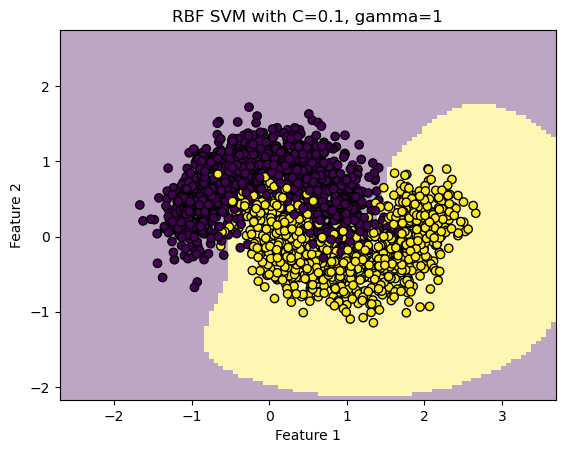

<Figure size 600x500 with 0 Axes>

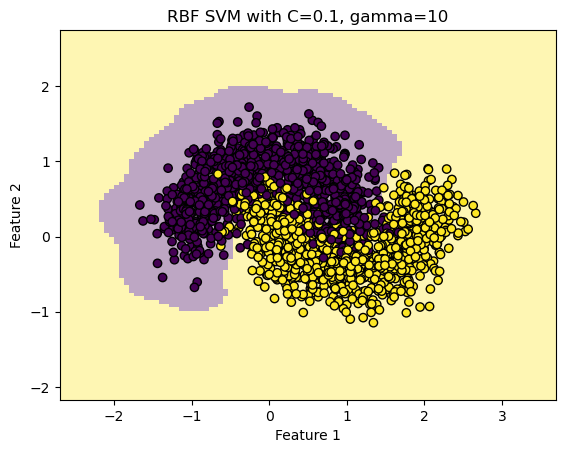

<Figure size 600x500 with 0 Axes>

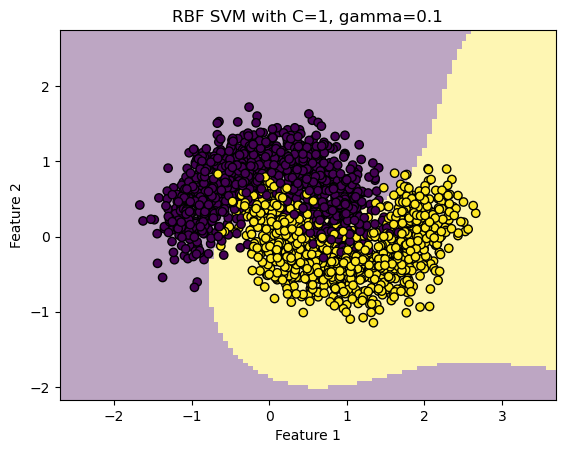

<Figure size 600x500 with 0 Axes>

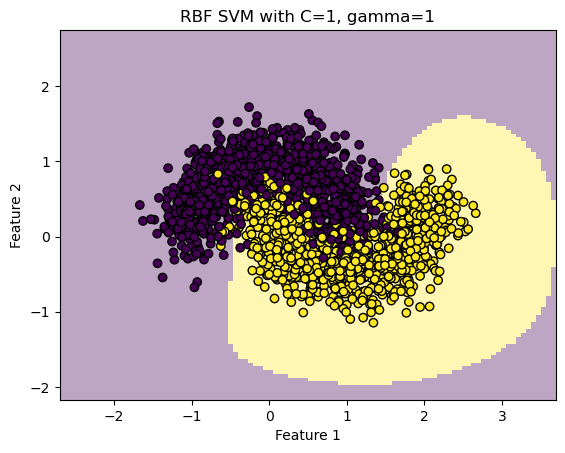

<Figure size 600x500 with 0 Axes>

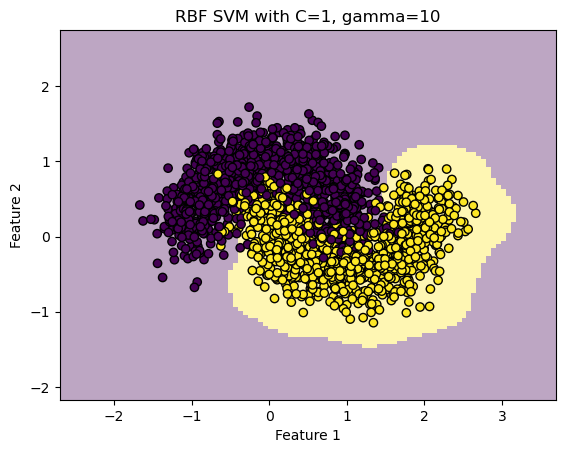

<Figure size 600x500 with 0 Axes>

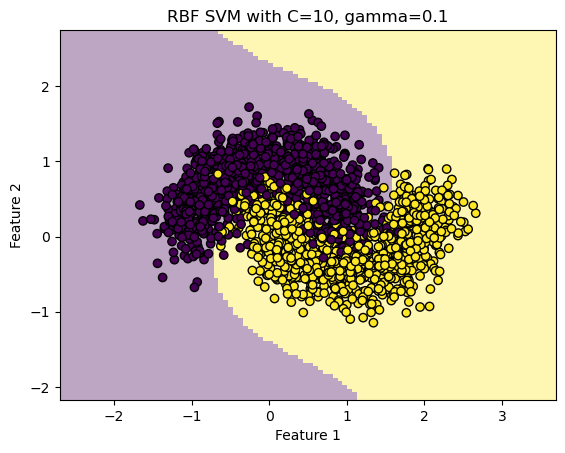

<Figure size 600x500 with 0 Axes>

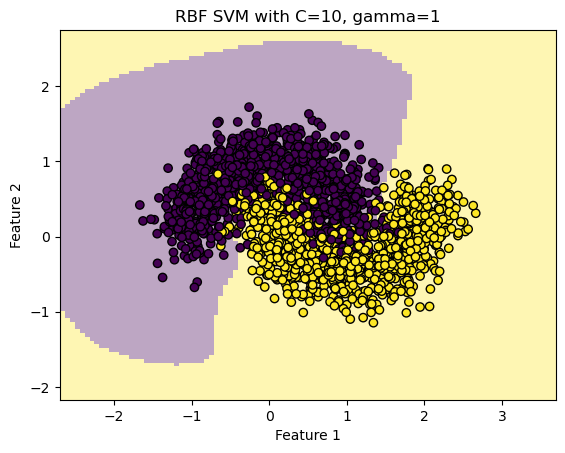

<Figure size 600x500 with 0 Axes>

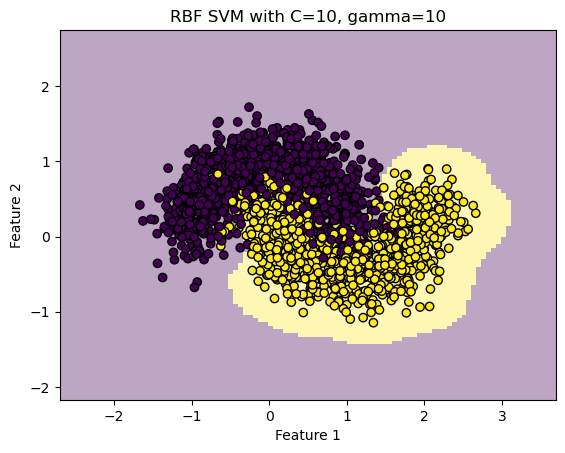

In [13]:
for C in C_grid:
    for gamma in gamma_grid:
        model = make_svm(kernel="rbf", C=C, gamma=gamma)
        plot_decision_boundary(
            model,
            X_train,
            y_train,
            title=f"RBF SVM with C={C}, gamma={gamma}"
        )


## 12. Effect of polynomial degree

The `degree` parameter only matters when:

```python
kernel="poly"
```

A higher degree creates a more flexible polynomial decision boundary.


In [14]:
degree_values = [2, 3, 4, 5, 6]

degree_results = []

for degree in degree_values:
    model = make_svm(kernel="poly", C=1.0, gamma="scale", degree=degree)
    train_acc, test_acc = evaluate_model(model, X_train, y_train, X_test, y_test)

    degree_results.append({
        "degree": degree,
        "train_accuracy": train_acc,
        "test_accuracy": test_acc
    })

pd.DataFrame(degree_results)


,degree,train_accuracy,test_accuracy
0,2,0.510952,0.495556
1,3,0.849048,0.864444
2,4,0.509048,0.488889
3,5,0.850476,0.861111
4,6,0.511905,0.505556


<Figure size 600x500 with 0 Axes>

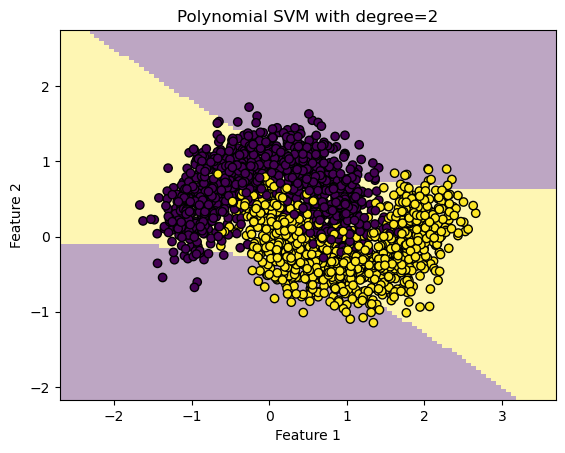

<Figure size 600x500 with 0 Axes>

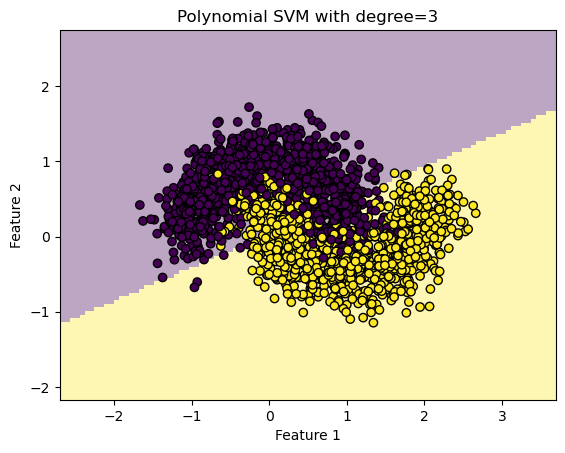

<Figure size 600x500 with 0 Axes>

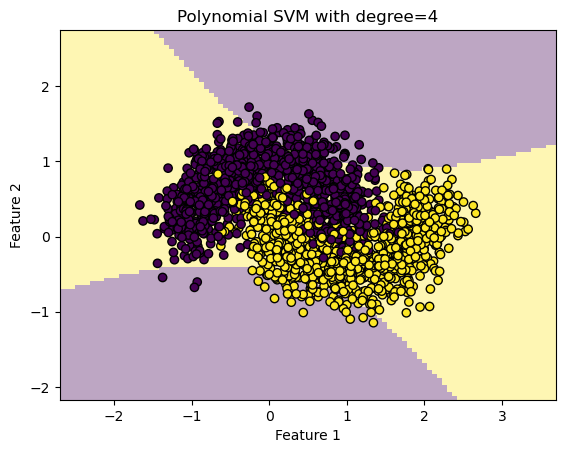

<Figure size 600x500 with 0 Axes>

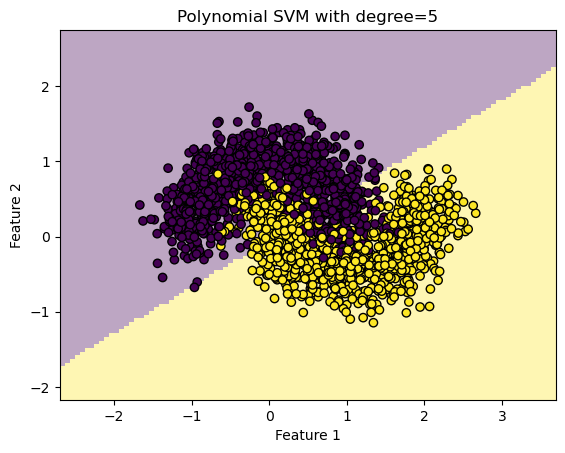

<Figure size 600x500 with 0 Axes>

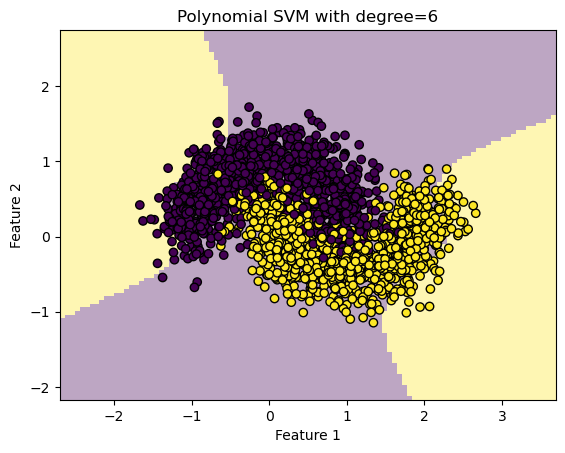

In [15]:
for degree in degree_values:
    model = make_svm(kernel="poly", C=1.0, gamma="scale", degree=degree)
    plot_decision_boundary(
        model,
        X_train,
        y_train,
        title=f"Polynomial SVM with degree={degree}"
    )


### Interpretation of `degree`

| Degree | Expected effect |
|---|---|
| Low degree | Simpler polynomial boundary |
| High degree | More complex polynomial boundary |

Higher degree is not automatically better.

It can increase model complexity and may reduce generalization.


## 13. Support vectors

The support vectors are the training points that define the decision boundary.

In scikit-learn, after fitting `SVC`, we can inspect:

```python
model.named_steps["svc"].support_vectors_
model.named_steps["svc"].n_support_
```

Because we use a pipeline with scaling, the support vectors are stored in the scaled feature space.


In [16]:
support_vector_model = make_svm(kernel="rbf", C=1.0, gamma=1.0)
support_vector_model.fit(X_train, y_train)

svc = support_vector_model.named_steps["svc"]

print("Number of support vectors per class:", svc.n_support_)
print("Total number of support vectors:", svc.support_vectors_.shape[0])


Number of support vectors per class: [192 195]
Total number of support vectors: 387


The number of support vectors can also give us some intuition.

If many training samples become support vectors, the decision boundary may depend on many points and the model may be more complex.


## 14. Final model evaluation

Let us choose one reasonable RBF SVM model and evaluate it on the test set.


Test accuracy: 0.9422222222222222

              precision    recall  f1-score   support

           0       0.96      0.92      0.94       450
           1       0.93      0.96      0.94       450

    accuracy                           0.94       900
   macro avg       0.94      0.94      0.94       900
weighted avg       0.94      0.94      0.94       900



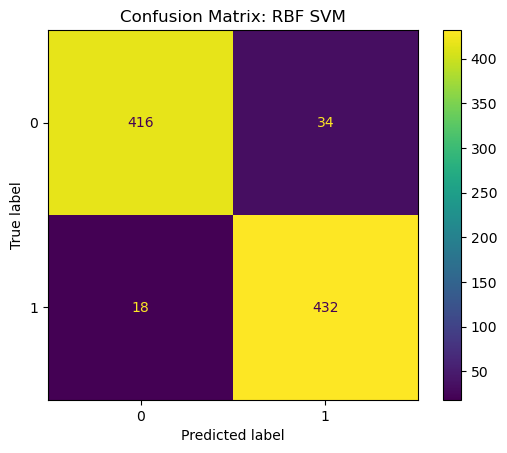

In [17]:
final_model = make_svm(kernel="rbf", C=1.0, gamma=1.0)

final_model.fit(X_train, y_train)

y_pred = final_model.predict(X_test)

print("Test accuracy:", accuracy_score(y_test, y_pred))
print()
print(classification_report(y_test, y_pred))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.title("Confusion Matrix: RBF SVM")
plt.show()


## 15. Hyperparameter tuning with GridSearchCV

Manual inspection is useful for teaching.

In real applications, we usually tune hyperparameters using cross-validation.

We search over:

- `kernel`,
- `C`,
- `gamma`,
- `degree`.

Because `degree` only matters for the polynomial kernel, some combinations are not meaningful but are harmless for this teaching example.


In [18]:
param_grid = {
    "svc__kernel": ["linear", "rbf", "poly"],
    "svc__C": [0.1, 1, 10, 100],
    "svc__gamma": ["scale", 0.01, 0.1, 1, 10],
    "svc__degree": [2, 3, 4]
}

pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svc", SVC())
])

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1,
    return_train_score=True
)

grid_search.fit(X_train, y_train)

print("Best parameters:")
print(grid_search.best_params_)
print()
print("Best cross-validation accuracy:")
print(grid_search.best_score_)


Best parameters:
{'svc__C': 1, 'svc__degree': 2, 'svc__gamma': 'scale', 'svc__kernel': 'rbf'}

Best cross-validation accuracy:
0.9285714285714286


In [19]:
grid_results = pd.DataFrame(grid_search.cv_results_)

selected_columns = [
    "param_svc__kernel",
    "param_svc__C",
    "param_svc__gamma",
    "param_svc__degree",
    "mean_train_score",
    "mean_test_score",
    "rank_test_score"
]

grid_results[selected_columns].sort_values("rank_test_score").head(10)


,param_svc__kernel,param_svc__C,param_svc__gamma,param_svc__degree,mean_train_score,mean_test_score,rank_test_score
61,rbf,1.0,scale,3,0.930119,0.928571,1
46,rbf,1.0,scale,2,0.930119,0.928571,1
76,rbf,1.0,scale,4,0.930119,0.928571,1
55,rbf,1.0,1,2,0.931429,0.928095,4
85,rbf,1.0,1,4,0.931429,0.928095,4
91,rbf,10.0,scale,2,0.930952,0.928095,4
70,rbf,1.0,1,3,0.931429,0.928095,4
115,rbf,10.0,1,3,0.933452,0.928095,4
100,rbf,10.0,1,2,0.933452,0.928095,4
106,rbf,10.0,scale,3,0.930952,0.928095,4


Test accuracy of best model: 0.9433333333333334

              precision    recall  f1-score   support

           0       0.96      0.92      0.94       450
           1       0.93      0.96      0.94       450

    accuracy                           0.94       900
   macro avg       0.94      0.94      0.94       900
weighted avg       0.94      0.94      0.94       900



<Figure size 600x500 with 0 Axes>

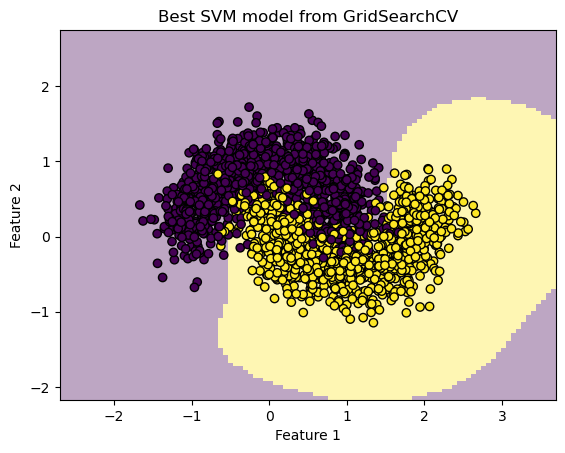

In [20]:
best_model = grid_search.best_estimator_

best_model.fit(X_train, y_train)

y_pred_best = best_model.predict(X_test)

print("Test accuracy of best model:", accuracy_score(y_test, y_pred_best))
print()
print(classification_report(y_test, y_pred_best))

plot_decision_boundary(
    best_model,
    X_train,
    y_train,
    title="Best SVM model from GridSearchCV"
)


## 16. Class imbalance and `class_weight`

SVMs can also be used with imbalanced datasets.

When one class is much more frequent than the other, the decision boundary may favor the majority class.

The parameter:

```python
class_weight="balanced"
```

automatically gives higher penalty to the minority class.


Class distribution:
0    250
1     50
Name: count, dtype: int64


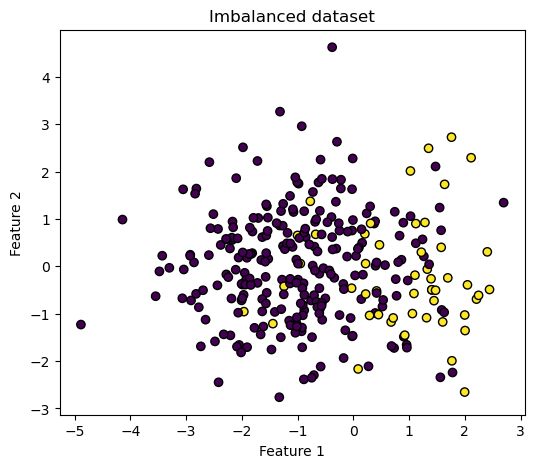

In [21]:
X_imb, y_imb = make_blobs(
    n_samples=[250, 50],
    centers=[[-1, 0], [1, 0]],
    cluster_std=[1.2, 1.2],
    random_state=42
)

print("Class distribution:")
print(pd.Series(y_imb).value_counts().sort_index())

plt.figure(figsize=(6, 5))
plt.scatter(X_imb[:, 0], X_imb[:, 1], c=y_imb, edgecolor="k")
plt.title("Imbalanced dataset")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()


In [22]:
X_imb_train, X_imb_test, y_imb_train, y_imb_test = train_test_split(
    X_imb,
    y_imb,
    test_size=0.30,
    random_state=42,
    stratify=y_imb
)

model_no_weight = make_svm(kernel="linear", C=1.0, class_weight=None)
model_balanced = make_svm(kernel="linear", C=1.0, class_weight="balanced")

for name, model in [
    ("No class_weight", model_no_weight),
    ("class_weight='balanced'", model_balanced)
]:
    model.fit(X_imb_train, y_imb_train)
    pred = model.predict(X_imb_test)

    print("=" * 70)
    print(name)
    print("Accuracy:", accuracy_score(y_imb_test, pred))
    print(classification_report(y_imb_test, pred))


No class_weight
Accuracy: 0.8888888888888888
              precision    recall  f1-score   support

           0       0.92      0.95      0.93        75
           1       0.69      0.60      0.64        15

    accuracy                           0.89        90
   macro avg       0.81      0.77      0.79        90
weighted avg       0.88      0.89      0.89        90

class_weight='balanced'
Accuracy: 0.7666666666666667
              precision    recall  f1-score   support

           0       0.95      0.76      0.84        75
           1       0.40      0.80      0.53        15

    accuracy                           0.77        90
   macro avg       0.68      0.78      0.69        90
weighted avg       0.86      0.77      0.79        90



<Figure size 600x500 with 0 Axes>

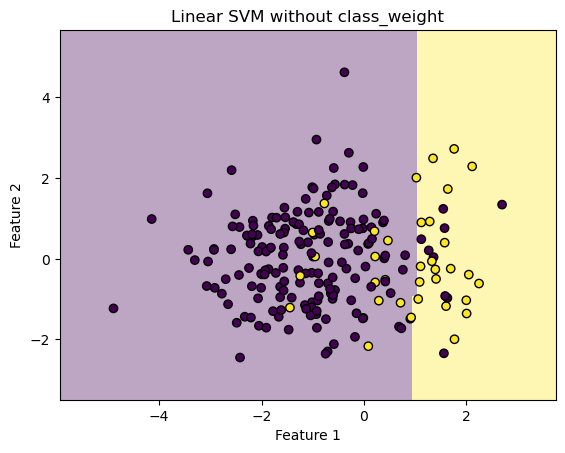

<Figure size 600x500 with 0 Axes>

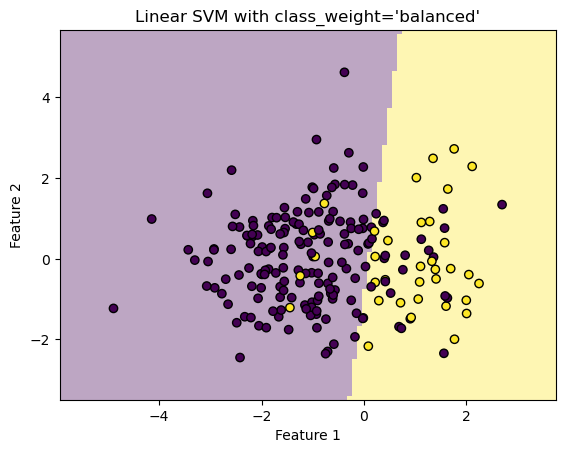

In [23]:
plot_decision_boundary(
    model_no_weight,
    X_imb_train,
    y_imb_train,
    title="Linear SVM without class_weight"
)

plot_decision_boundary(
    model_balanced,
    X_imb_train,
    y_imb_train,
    title="Linear SVM with class_weight='balanced'"
)


### Interpretation of `class_weight`

Without class weighting, the SVM may prefer the majority class.

With `class_weight="balanced"`, the minority class receives a stronger penalty for errors.

This can improve recall for the minority class, although it may reduce overall accuracy.


## 17. Practical recommendations

### Use feature scaling

Always consider scaling features before using SVMs.

```python
Pipeline([
    ("scaler", StandardScaler()),
    ("svc", SVC())
])
```

### Start simple

Good starting model:

```python
SVC(kernel="rbf", C=1.0, gamma="scale")
```

### Tune important parameters

For RBF SVMs:

- tune `C`,
- tune `gamma`.

For polynomial SVMs:

- tune `C`,
- tune `gamma`,
- tune `degree`.

### Watch for overfitting

Signs of overfitting:

- very complex decision boundary,
- very high training accuracy,
- lower test accuracy.

### For large datasets

`SVC` can be slow for large datasets.

For large linear problems, consider:

```python
LinearSVC()
```

or stochastic linear models such as `SGDClassifier`.


## 18. Exercises

### Exercise 1: Kernel comparison

Train SVMs with:

```python
kernels = ["linear", "poly", "rbf", "sigmoid"]
```

For each model:

1. plot the decision boundary,
2. compute training accuracy,
3. compute test accuracy,
4. explain whether the model underfits or overfits.

---

### Exercise 2: Effect of `C`

Use the RBF kernel and test:

```python
C_values = [0.001, 0.01, 0.1, 1, 10, 100]
```

Questions:

1. Which value gives the smoothest boundary?
2. Which value gives the most complex boundary?
3. Which value gives the best test accuracy?

---

### Exercise 3: Effect of `gamma`

Use the RBF kernel and test:

```python
gamma_values = [0.001, 0.01, 0.1, 1, 10, 100]
```

Questions:

1. What happens when `gamma` is too small?
2. What happens when `gamma` is too large?
3. Which value gives the best balance?

---

### Exercise 4: Polynomial degree

Use the polynomial kernel and test:

```python
degree_values = [2, 3, 4, 5, 6]
```

Questions:

1. How does the boundary change?
2. Does higher degree always improve performance?
3. Which degree gives the best generalization?

---

### Exercise 5: Grid search

Use `GridSearchCV` to tune `kernel`, `C`, `gamma`, and `degree`.

Then answer:

1. What are the best parameters?
2. What is the cross-validation accuracy?
3. What is the test accuracy?
4. Does the best model look reasonable visually?


## 19. Summary

Support Vector Machines are powerful supervised learning models.

Key ideas:

- SVMs try to maximize the margin.
- Support vectors define the decision boundary.
- Kernels allow SVMs to learn non-linear boundaries.
- `C` controls the penalty for mistakes.
- `gamma` controls how local the influence of points is.
- `degree` controls polynomial complexity.
- `class_weight="balanced"` can help with imbalanced data.
- Scaling is usually necessary.
- Cross-validation should be used for serious hyperparameter tuning.
